# MATH7810 Python for Data Science
## Individual Case Study — Medical Cost Personal Dataset

**Dataset:** MedicalCost.xlsx  
**Analysis outcome:** `charges` (medical insurance charges)

> **Important submission reminder:** Replace the notebook filename with `[student number]_[full name without spaces]`. Do not type your student number or name inside the notebook. The assignment requires the notebook to be executed with all outputs visible, then saved and zipped. Submit the ZIP containing the notebook only; do not include the Excel data file.

This notebook follows the four parts in the case-study instruction. The analysis is written in English to match the required report language.

# Part I — Exploratory Data Analysis

## 1. Introduction to the dataset

The dataset contains individual-level information related to medical insurance charges. The variables include demographic characteristics (`age`, `sex`, `children`), health/lifestyle information (`bmi`, `smoker`), geographic information (`region`), and the medical insurance charge (`charges`). From a business perspective, understanding how customer characteristics are associated with insurance charges may help insurers understand risk patterns and communicate how premiums vary across customer groups.

The analysis below first checks the data structure, variable types, missing values, and possible duplicate records. No observation will be removed solely because its value is large; extreme values may be genuine insurance claims/charges.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

# Put MedicalCost.xlsx in the same folder as this notebook before running.
DATA_PATH = "MedicalCost.xlsx"
df = pd.read_excel(DATA_PATH)

# Standardize column labels and remove accidental leading/trailing spaces.
df.columns = df.columns.str.strip()

print("Dataset shape (observations, variables):", df.shape)
print("\\nData types:")
display(df.dtypes.to_frame("Data type"))
print("\\nFirst five observations:")
display(df.head())
print("\\nMissing values by variable:")
display(df.isna().sum().to_frame("Missing values"))
print("\\nNumber of duplicated rows:", df.duplicated().sum())


Dataset shape (observations, variables): (1338, 7)
\nData types:


,Data type
age,int64
sex,object
bmi,float64
children,int64
smoker,object
region,object
charges,float64


\nFirst five observations:


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


\nMissing values by variable:


,Missing values
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


\nNumber of duplicated rows: 1


### Data quality and preparation

The supplied workbook contains 1,338 observations and 7 variables. The initial check found no missing values and no duplicated rows. Therefore, no imputation or duplicate removal is required. The original observations are retained. The categorical variables are treated as categories for group summaries and visualizations; numerical variables are retained in numeric form.

In [2]:
# Explicitly identify variable roles for subsequent analysis.
numeric_vars = ["age", "bmi", "children", "charges"]
categorical_vars = ["sex", "smoker", "region"]

for col in categorical_vars:
    df[col] = df[col].astype("category")

print("Numeric variables:", numeric_vars)
print("Categorical variables:", categorical_vars)
print("Missing values after preparation:", int(df.isna().sum().sum()))


Numeric variables: ['age', 'bmi', 'children', 'charges']
Categorical variables: ['sex', 'smoker', 'region']
Missing values after preparation: 0


## 2. Numerical descriptive statistics

For numerical variables, the table reports the sample size, mean, standard deviation, minimum, quartiles, and maximum. For categorical variables, percentages are reported to show the composition of the sample.

In [3]:
print("Descriptive statistics for numerical variables:")
display(df[numeric_vars].describe().T)

print("Categorical variable counts and percentages:")
for col in categorical_vars:
    summary = pd.DataFrame({
        "Count": df[col].value_counts(dropna=False),
        "Percentage (%)": df[col].value_counts(normalize=True, dropna=False) * 100
    })
    display(summary.round(2))


Descriptive statistics for numerical variables:


,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.207025,14.049960,18.0000,27.00000,39.000,51.000000,64.00000
bmi,1338.0,30.663397,6.098187,15.9600,26.29625,30.400,34.693750,53.13000
children,1338.0,1.094918,1.205493,0.0000,0.00000,1.000,2.000000,5.00000
charges,1338.0,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


Categorical variable counts and percentages:


,Count,Percentage (%)
sex,,
male,676,50.52
female,662,49.48


,Count,Percentage (%)
smoker,,
no,1064,79.52
yes,274,20.48


,Count,Percentage (%)
region,,
southeast,364,27.20
northwest,325,24.29
southwest,325,24.29
northeast,324,24.22


### Descriptive-statistics interpretation

The mean medical insurance charge is approximately **$13,270.42**, while the standard deviation is approximately **$12,110.01**. The large standard deviation indicates substantial variation in charges across individuals. The median charge is lower than the mean, suggesting a right-skewed distribution in which a subset of individuals has particularly high charges. This is important for insurers because the mean alone may not describe the typical customer very well.

The sample includes 1,064 non-smokers and 274 smokers. This group imbalance should be kept in mind when comparing the two groups. Descriptive differences are not, by themselves, proof that smoking causes higher charges.

## 3. Exploratory data visualization

Each figure includes a descriptive title and axis labels. The interpretations explain the business relevance while avoiding causal claims.

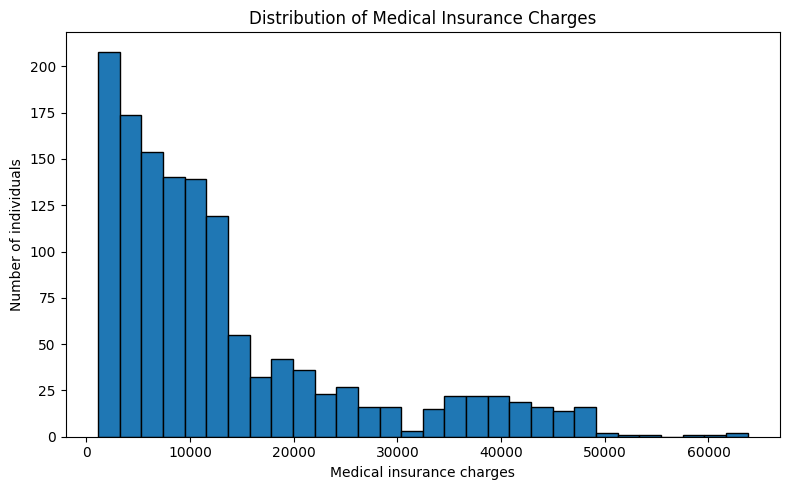

In [4]:
# Figure 1: Distribution of medical insurance charges
plt.figure(figsize=(8, 5))
plt.hist(df["charges"], bins=30, edgecolor="black")
plt.title("Distribution of Medical Insurance Charges")
plt.xlabel("Medical insurance charges")
plt.ylabel("Number of individuals")
plt.tight_layout()
plt.show()


**Figure 1 interpretation and business implication:** The distribution of charges is strongly right-skewed: many individuals have relatively lower charges, while a smaller number have very high charges. For an insurer, this means that the average charge may be influenced by a relatively small high-cost segment. Reporting the median and spread alongside the mean is therefore useful.

/tmp/ipykernel_386/139664076.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(plot_data, labels=["Non-smoker", "Smoker"], showfliers=False)


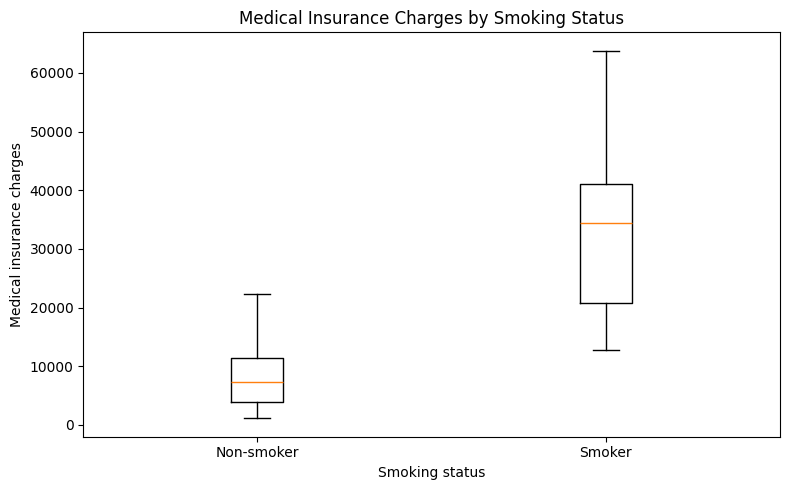

In [5]:
# Figure 2: Charges by smoking status
smoking_order = ["no", "yes"]
plot_data = [df.loc[df["smoker"] == group, "charges"] for group in smoking_order]
plt.figure(figsize=(8, 5))
plt.boxplot(plot_data, labels=["Non-smoker", "Smoker"], showfliers=False)
plt.title("Medical Insurance Charges by Smoking Status")
plt.xlabel("Smoking status")
plt.ylabel("Medical insurance charges")
plt.tight_layout()
plt.show()


**Figure 2 interpretation and business implication:** The smoker group has a much higher distribution of medical insurance charges than the non-smoker group. The difference is visible in the medians and in the overall spread. Smoking status may therefore be an important characteristic for insurers to examine when studying cost patterns. The plot is descriptive and does not establish causation.

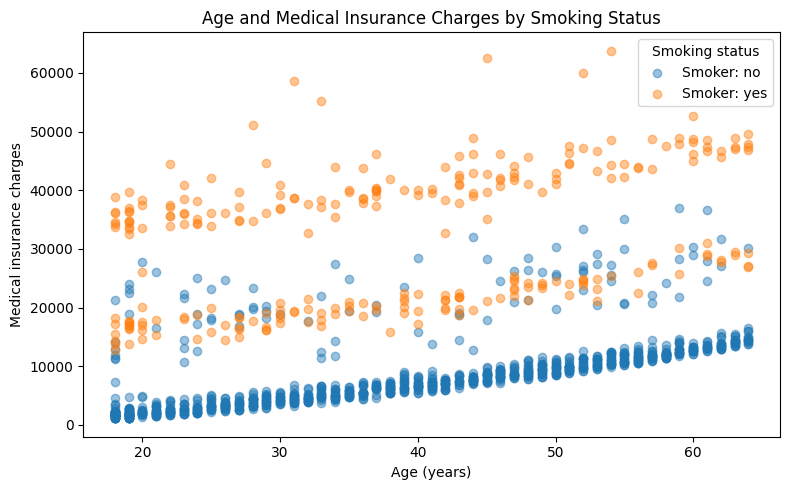

In [6]:
# Figure 3: Age and medical insurance charges
plt.figure(figsize=(8, 5))
for group, color in [("no", None), ("yes", None)]:
    subset = df[df["smoker"] == group]
    plt.scatter(subset["age"], subset["charges"], alpha=0.45, label=f"Smoker: {group}")
plt.title("Age and Medical Insurance Charges by Smoking Status")
plt.xlabel("Age (years)")
plt.ylabel("Medical insurance charges")
plt.legend(title="Smoking status")
plt.tight_layout()
plt.show()


**Figure 3 interpretation and business implication:** Charges tend to show a positive association with age, although there is substantial variation among people of the same age. The points also show that smoking status separates many observations into different charge ranges. Insurers should therefore avoid relying on age alone when considering cost patterns.

# Part II — Research Questions and Statistical Analysis

## AI prompt and AI-proposed candidate questions

**Prompt used:** “I am analysing the Medical Cost Personal Dataset, which contains age, sex, BMI, number of children, smoking status, region, and medical insurance charges. Propose three practical, business-relevant research questions that can be answered using descriptive statistics, confidence intervals, hypothesis tests, Pearson correlation, or simple linear regression.”

**AI-proposed candidate questions:**
1. Do mean medical insurance charges differ between smokers and non-smokers?
2. Is age linearly associated with medical insurance charges?
3. Do mean medical insurance charges differ between male and female individuals?

**Important academic-integrity step:** The assignment requires you to propose three questions *without AI first*. Add your own three original questions below, based on what you independently thought before consulting AI. Do not claim that the AI-proposed questions were your original ideas.

**My three questions before using AI (complete this section yourself):**
- My question 1: [Write your own question]
- My question 2: [Write your own question]
- My question 3: [Write your own question]

## Final selected questions and rationale

The following three questions are used for the statistical analysis in this notebook. They are feasible with the available variables and have potential relevance to insurance cost analysis.

| Final research question | Main origin | Why it was retained |
|---|---|---|
| Do mean charges differ between smokers and non-smokers? | AI candidate / revise if merged with your idea | Smoking status and charges are directly observed; a two-group mean comparison is feasible. |
| Is age associated with charges? | AI candidate / revise if merged with your idea | Both variables are numerical; Pearson correlation and simple linear regression can quantify the linear association. |
| Do mean charges differ between males and females? | AI candidate / revise if merged with your idea | Sex and charges are observed; a two-group mean comparison is feasible. |

**Before submission:** Change the “Main origin” entries to accurately reflect whether each final question came mainly from you, AI, or a merge. Explain your actual reason for keeping each question.

## Research Question 1 — Smoking status and medical insurance charges

**Question:** Do mean medical insurance charges differ between smokers and non-smokers?

We use Welch's independent two-sample t-test. It is appropriate for comparing the means of two independent groups and does not require the two population variances to be equal.

Let \(\mu_S\) be the population mean charge for smokers and \(\mu_N\) be the population mean charge for non-smokers.

- Null hypothesis: \(H_0: \mu_S - \mu_N = 0\)
- Alternative hypothesis: \(H_1: \mu_S - \mu_N \ne 0\)

The Welch test statistic is

\[
t = \frac{\bar{x}_S-\bar{x}_N}{\sqrt{s_S^2/n_S+s_N^2/n_N}}.
\]

We use a two-sided significance level of 5%.

In [7]:
smokers = df.loc[df["smoker"] == "yes", "charges"]
non_smokers = df.loc[df["smoker"] == "no", "charges"]

t_stat_1, p_value_1 = stats.ttest_ind(smokers, non_smokers, equal_var=False)
difference_1 = smokers.mean() - non_smokers.mean()
se_1 = np.sqrt(smokers.var(ddof=1)/len(smokers) + non_smokers.var(ddof=1)/len(non_smokers))
df_welch_1 = (smokers.var(ddof=1)/len(smokers) + non_smokers.var(ddof=1)/len(non_smokers))**2 / (
    (smokers.var(ddof=1)/len(smokers))**2/(len(smokers)-1) +
    (non_smokers.var(ddof=1)/len(non_smokers))**2/(len(non_smokers)-1)
)
critical_1 = stats.t.ppf(0.975, df_welch_1)
ci_1 = (difference_1 - critical_1*se_1, difference_1 + critical_1*se_1)

print(f"Smokers: n={len(smokers)}, mean=${smokers.mean():,.2f}, SD=${smokers.std(ddof=1):,.2f}")
print(f"Non-smokers: n={len(non_smokers)}, mean=${non_smokers.mean():,.2f}, SD=${non_smokers.std(ddof=1):,.2f}")
print(f"Mean difference (smokers - non-smokers) = ${difference_1:,.2f}")
print(f"Welch t statistic = {t_stat_1:.4f}")
print(f"Welch degrees of freedom = {df_welch_1:.2f}")
print(f"p-value = {p_value_1:.4e}")
print(f"95% CI for mean difference = (${ci_1[0]:,.2f}, ${ci_1[1]:,.2f})")


Smokers: n=274, mean=$32,050.23, SD=$11,541.55
Non-smokers: n=1064, mean=$8,434.27, SD=$5,993.78
Mean difference (smokers - non-smokers) = $23,615.96
Welch t statistic = 32.7519
Welch degrees of freedom = 311.85
p-value = 5.8895e-103
95% CI for mean difference = ($22,197.21, $25,034.71)


### Research Question 1 — Result and business interpretation

The sample mean charge for smokers is approximately **$32,050.23**, compared with **$8,434.27** for non-smokers. The estimated mean difference (smokers minus non-smokers) is approximately **$23,615.96**. Welch's test gives \(t \approx 32.75\) and a p-value far below 0.05. The 95% confidence interval for the mean difference is approximately **$22,197.21 to $25,034.71**.

We reject the null hypothesis and conclude that the sample provides strong statistical evidence of a difference in mean charges between smokers and non-smokers. In this dataset, smokers have substantially higher average charges. This association may be relevant to insurers' cost-risk analysis. However, the analysis is observational and does not prove that smoking alone causes the difference; other characteristics may also be related to charges.

## Research Question 2 — Age and medical insurance charges

**Question:** Is age linearly associated with medical insurance charges?

We use Pearson's correlation to measure the strength and direction of a linear association. We also fit a simple linear regression to estimate the change in predicted charges associated with a one-year increase in age.

- Null hypothesis: \(H_0: \rho = 0\) (no population linear correlation)
- Alternative hypothesis: \(H_1: \rho \ne 0\)

The sample Pearson correlation is

\[
r = \frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}
{\sqrt{\sum_{i=1}^{n}(x_i-\bar{x})^2\sum_{i=1}^{n}(y_i-\bar{y})^2}}.
\]

For testing the correlation, the test statistic is

\[
t = r\sqrt{\frac{n-2}{1-r^2}},
\]

with \(n-2\) degrees of freedom under the null hypothesis. The simple linear regression model is \(charges_i = \beta_0 + \beta_1 age_i + \varepsilon_i\).

In [8]:
r_age, p_age = stats.pearsonr(df["age"], df["charges"])
reg_age = stats.linregress(df["age"], df["charges"])
n_age = len(df)
t_age = r_age * np.sqrt((n_age - 2)/(1-r_age**2))

print(f"Pearson correlation r = {r_age:.4f}")
print(f"Correlation test statistic t = {t_age:.4f}")
print(f"Degrees of freedom = {n_age-2}")
print(f"p-value = {p_age:.4e}")
print(f"Regression intercept = ${reg_age.intercept:,.2f}")
print(f"Regression slope = ${reg_age.slope:,.2f} per additional year")
print(f"R-squared = {reg_age.rvalue**2:.4f}")
print(f"95% CI for slope = (${reg_age.slope-1.96*reg_age.stderr:,.2f}, ${reg_age.slope+1.96*reg_age.stderr:,.2f})")


Pearson correlation r = 0.2990
Correlation test statistic t = 11.4531
Degrees of freedom = 1336
p-value = 4.8867e-29
Regression intercept = $3,165.89
Regression slope = $257.72 per additional year
R-squared = 0.0894
95% CI for slope = ($213.62, $301.83)


### Research Question 2 — Result and business interpretation

The sample Pearson correlation is approximately **0.299**, indicating a positive but relatively weak linear association between age and charges. The p-value is far below 0.05, so we reject the null hypothesis of zero population linear correlation. The fitted regression slope is approximately **$257.72**: in this simple model, each additional year of age is associated with about $257.72 higher predicted charges on average.

The model's \(R^2\) is approximately **0.089**, meaning age alone explains only about 8.9% of the sample variation in charges in this linear model. Although the association is statistically significant, it is not strong enough to use age as a stand-alone predictor. The relationship is an association, not proof of causation, and other variables such as smoking status may be important.

## Research Question 3 — Sex and medical insurance charges

**Question:** Do mean medical insurance charges differ between male and female individuals?

We use Welch's independent two-sample t-test because the two sex groups are independent and equal population variances are not assumed.

Let \(\mu_M\) be the population mean charge for males and \(\mu_F\) be the population mean charge for females.

- Null hypothesis: \(H_0: \mu_M - \mu_F = 0\)
- Alternative hypothesis: \(H_1: \mu_M - \mu_F \ne 0\)

The test statistic is

\[
t = \frac{\bar{x}_M-\bar{x}_F}{\sqrt{s_M^2/n_M+s_F^2/n_F}}.
\]

We use a two-sided significance level of 5%.

In [9]:
males = df.loc[df["sex"] == "male", "charges"]
females = df.loc[df["sex"] == "female", "charges"]

t_stat_3, p_value_3 = stats.ttest_ind(males, females, equal_var=False)
difference_3 = males.mean() - females.mean()
se_3 = np.sqrt(males.var(ddof=1)/len(males) + females.var(ddof=1)/len(females))
df_welch_3 = (males.var(ddof=1)/len(males) + females.var(ddof=1)/len(females))**2 / (
    (males.var(ddof=1)/len(males))**2/(len(males)-1) +
    (females.var(ddof=1)/len(females))**2/(len(females)-1)
)
critical_3 = stats.t.ppf(0.975, df_welch_3)
ci_3 = (difference_3 - critical_3*se_3, difference_3 + critical_3*se_3)

print(f"Males: n={len(males)}, mean=${males.mean():,.2f}, SD=${males.std(ddof=1):,.2f}")
print(f"Females: n={len(females)}, mean=${females.mean():,.2f}, SD=${females.std(ddof=1):,.2f}")
print(f"Mean difference (males - females) = ${difference_3:,.2f}")
print(f"Welch t statistic = {t_stat_3:.4f}")
print(f"Welch degrees of freedom = {df_welch_3:.2f}")
print(f"p-value = {p_value_3:.4f}")
print(f"95% CI for mean difference = (${ci_3[0]:,.2f}, ${ci_3[1]:,.2f})")


Males: n=676, mean=$13,956.75, SD=$12,971.03
Females: n=662, mean=$12,569.58, SD=$11,128.70
Mean difference (males - females) = $1,387.17
Welch t statistic = 2.1009
Welch degrees of freedom = 1313.36
p-value = 0.0358
95% CI for mean difference = ($91.86, $2,682.49)


### Research Question 3 — Result and business interpretation

The sample mean charge for males is approximately **$13,956.75**, compared with **$12,569.58** for females. The estimated difference (males minus females) is approximately **$1,387.17**. Welch's test gives \(t \approx 2.10\) and a p-value of approximately **0.0358**, which is below 0.05. The 95% confidence interval for the mean difference is approximately **$91.86 to $2,682.49**.

At the 5% significance level, we reject the null hypothesis and find evidence of a difference in mean charges between males and females in this sample. However, the difference is modest compared with the large variation within each group. The result should not be interpreted as evidence that sex itself causes higher charges. Other variables, especially smoking status and age, may partly explain the observed difference. A multivariable model would be needed to examine those factors jointly.

## Overall findings and limitations

Across the three questions, the largest observed mean-charge difference is between smokers and non-smokers. Age has a positive but weak linear association with charges. The male and female groups show a statistically significant difference in mean charges at the 5% level, but the size of that difference is relatively small compared with within-group variation.

These are observational data. The analyses identify associations and group differences, not causal effects. The dataset also contains a limited set of explanatory variables. In particular, the simple age regression does not control for smoking status, BMI, region, or number of children. Results should therefore be used as exploratory evidence rather than as a complete pricing model.

# Part III — Human–AI Partnership Reflective Essay (minimum 400 words)

**This section must be personalized before submission.** The assignment asks about your own prior Python experience, your experience using GitHub Codespaces/VS Code, one belief you tested, one Copilot suggestion you evaluated (not one of the research questions compared in Part II), and how Copilot affected your speed and confidence. I cannot truthfully invent these personal experiences for you.

Use the following draft structure. Replace every square-bracketed prompt with your own experience, and ensure the final essay is at least 400 words.

## 1. Learning Python when AI can generate code

Before this course, my experience with Python was [describe honestly: no experience / beginner / previous coursework and what you could do]. At the beginning of the case study, I felt [describe whether you questioned the need to learn Python when AI tools can generate code]. After using GitHub Copilot, my view [changed / did not change] because [give a specific example from your work]. I learned that generated code still needs a person to understand the variables, check whether the code matches the research question, and interpret the output correctly. For example, in this project I had to understand why the smoking comparison used Welch's two-sample t-test and why a small p-value did not establish causation. [Add what you personally found difficult or surprising.]

## 2. The environment I worked in

Before this course, I [had / had not] used an integrated development environment. My experience with GitHub Codespaces was [overwhelming / convenient / a mixture]. One challenging part was [describe a real challenge, such as locating files, understanding the terminal, installing packages, running notebook cells, or debugging an error]. The IDE feature I found most useful was [name a feature you actually used, such as notebook cells, code completion, terminal, variable explorer, or error highlighting], because [explain how it helped]. A specific example was [describe what happened and how you resolved it].

## 3. My judgement in this case study

### 3.1 A working belief I tested

At the start, I believed that [state one concrete belief about the dataset, a method, or a data pattern]. I tested this belief by [name the table, plot, descriptive statistic, or statistical check]. The result was [report the actual result from this notebook or another check you performed]. This [supported / did not support] my original belief, so I [kept / revised] it. This matters because [explain how it affects the way you interpret charges or your conclusions].

### 3.2 A Copilot suggestion I evaluated

I asked Copilot [describe a prompt about code, data cleaning, a plot, a test, or an interpretation; do not reuse the three research questions from Part II]. Copilot suggested [describe its actual suggestion]. I evaluated the suggestion by checking [whether the code ran, whether the variables were correct, whether the plot labels were meaningful, whether the statistical method's assumptions were appropriate, or whether the interpretation matched the output]. I decided to [keep / modify / reject] the suggestion because [give your reason and the specific change, if any].

### 3.3 Overall effect of Copilot

Overall, Copilot affected my speed by [describe the actual effect] and my confidence by [describe the actual effect]. It was particularly helpful when [give one example], but I still needed to [explain what you checked independently]. This case study showed me that AI can support coding and exploration, but responsibility for data quality, statistical choices, and business interpretation remains with me.

**Before submission:** Remove these instructions and all square-bracketed prompts. The final essay must reflect your own actual experience and contain at least 400 words.

# Part IV — References

1. Kaggle. (n.d.). *Medical Cost Personal Datasets*. https://www.kaggle.com/datasets/mirichoi0218/insurance
2. MATH7810 Python for Data Science. (2026/27). *Individual Case Study (AY2026/27)*. Course assignment instruction.
3. SciPy documentation. (n.d.). *scipy.stats.ttest_ind* and *scipy.stats.pearsonr*. https://docs.scipy.org/doc/scipy/reference/stats.html
4. pandas documentation. (n.d.). *pandas documentation*. https://pandas.pydata.org/docs/

Add any other websites, books, lecture notes, or data documentation that you actually consulted. Ensure that the final reference list matches the sources you used.

# Final submission checklist

- [ ] Replace the notebook filename with `[student number]_[full name without spaces].ipynb`.
- [ ] Do not put your student number or name inside the notebook.
- [ ] Add your own three pre-AI research questions and accurately identify the origin of each final question.
- [ ] Complete and personalize Part III; the essay must be at least 400 words.
- [ ] Check the Kaggle dataset page and add any other sources actually consulted.
- [ ] Put `MedicalCost.xlsx` in the same folder as the notebook if you need to rerun it.
- [ ] Run every code cell from top to bottom and confirm there are no errors.
- [ ] Save the notebook with all tables, printed results, and figures visible.
- [ ] Zip the notebook only. Do not include the Excel data file or other documents in the ZIP.
- [ ] Submit the ZIP via Moodle by 11:59 PM, 22 November 2026.